# Consultar por precio y destino

Datos de vuelos de ejemplo — Pablo Adasme

Filtra vuelos por intervalo de precio y país de destino, y compara sus precios.

[Volver al índice](00_indice.ipynb)

## 1. Conexión

En Kibana (`http://localhost:5601`), la consola de Dev Tools envía peticiones a Elasticsearch. Python hace la misma petición directamente, sin pasar por Kibana: desde Jupyter en Docker Compose, `elasticsearch` es el nombre del servicio y `9200` su puerto. Si el kernel corre en el equipo anfitrión, usa `http://localhost:9200`.

El índice de ejemplo debe existir antes de ejecutar la consulta. Este cuaderno no instala datos ni modifica el clúster.

In [1]:
import json
from urllib.error import HTTPError, URLError
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt

url_elasticsearch = "http://elasticsearch:9200"

## 2. Configuración

En `kibana_sample_data_flights`, `AvgTicketPrice` es numérico y `DestCountry` es un código de país (`AU` para Australia). El filtro `range` incluye ambos límites (`gte` y `lte`); `term` exige el código exacto. Ambos filtros deben cumplirse. `size` limita los vuelos devueltos.

Edita estos valores para cambiar la consulta de Python.

In [2]:
indice = "kibana_sample_data_flights"
precio_minimo = 500
precio_maximo = 900
pais_destino = "AU"
limite = 20

cuerpo = {
    "size": limite,
    "_source": ["FlightNum", "DestCountry", "AvgTicketPrice"],
    "query": {
        "bool": {
            "filter": [
                {"range": {"AvgTicketPrice": {"gte": precio_minimo, "lte": precio_maximo}}},
                {"term": {"DestCountry": pais_destino}},
            ]
        }
    },
    "sort": [{"AvgTicketPrice": {"order": "asc"}}],
}

## 3. Ejecución

Copia el bloque entero en la consola de Dev Tools para ejecutar la consulta con los valores predeterminados.

```http
GET kibana_sample_data_flights/_search
{
  "size": 20,
  "_source": [
    "FlightNum",
    "DestCountry",
    "AvgTicketPrice"
  ],
  "query": {
    "bool": {
      "filter": [
        {
          "range": {
            "AvgTicketPrice": {
              "gte": 500,
              "lte": 900
            }
          }
        },
        {
          "term": {
            "DestCountry": "AU"
          }
        }
      ]
    }
  },
  "sort": [
    {
      "AvgTicketPrice": {
        "order": "asc"
      }
    }
  ]
}
```

En Jupyter, ejecuta la siguiente celda. Imprime la URL y el JSON efectivos antes de enviar la petición de solo lectura.

In [5]:
url = f"{url_elasticsearch.rstrip('/')}/{indice}/_search"
cuerpo_json = json.dumps(cuerpo, ensure_ascii=False, indent=2)
print(f"GET {url}")
print(cuerpo_json)

solicitud = Request(
    url,
    data=cuerpo_json.encode("utf-8"),
    headers={"Content-Type": "application/json"},
    method="GET",
)

resultado = None
try:
    with urlopen(solicitud, timeout=10) as respuesta:
        resultado = json.load(respuesta)
except HTTPError as error:
    if error.code == 404:
        print(f"No se encontró el índice {indice}. Comprueba que el conjunto de ejemplo esté disponible.")
    else:
        print(f"Elasticsearch respondió con el código HTTP {error.code}. Revisa el índice y la consulta.")
except (URLError, TimeoutError):
    print("No se pudo conectar con Elasticsearch. Revisa la URL y el estado del servicio.")

GET http://elasticsearch:9200/kibana_sample_data_flights/_search
{
  "size": 20,
  "_source": [
    "FlightNum",
    "DestCountry",
    "AvgTicketPrice"
  ],
  "query": {
    "bool": {
      "filter": [
        {
          "range": {
            "AvgTicketPrice": {
              "gte": 500,
              "lte": 900
            }
          }
        },
        {
          "term": {
            "DestCountry": "AU"
          }
        }
      ]
    }
  },
  "sort": [
    {
      "AvgTicketPrice": {
        "order": "asc"
      }
    }
  ]
}


## 4. Visualización

Cada punto representa un vuelo devuelto. Las líneas marcan los límites inclusivos; los puntos deben quedar dentro del intervalo y su país debe coincidir con el del título.

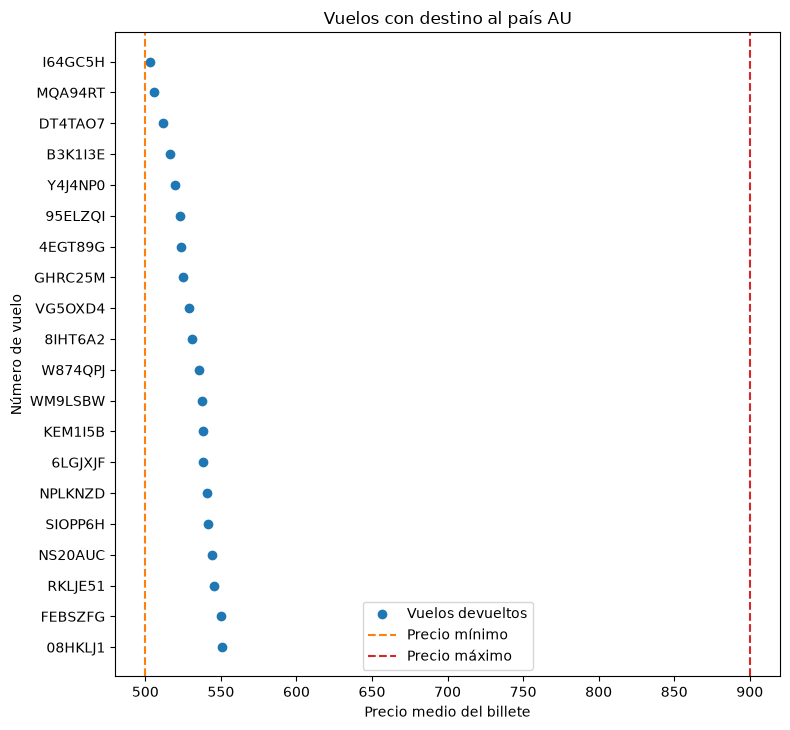

In [6]:
if resultado is not None:
    vuelos = [hit["_source"] for hit in resultado["hits"]["hits"]]
    if not vuelos:
        print("No se encontraron vuelos para ese destino e intervalo de precios.")
    else:
        etiquetas = [vuelo["FlightNum"] for vuelo in vuelos]
        precios = [vuelo["AvgTicketPrice"] for vuelo in vuelos]
        fig, ax = plt.subplots(figsize=(8, max(3, 0.32 * len(vuelos) + 1)))
        ax.scatter(precios, range(len(vuelos)), label="Vuelos devueltos")
        ax.axvline(precio_minimo, color="tab:orange", linestyle="--", label="Precio mínimo")
        ax.axvline(precio_maximo, color="tab:red", linestyle="--", label="Precio máximo")
        ax.set_yticks(range(len(vuelos)), etiquetas)
        ax.invert_yaxis()
        ax.set(xlabel="Precio medio del billete", ylabel="Número de vuelo",
               title=f"Vuelos con destino al país {pais_destino}")
        ax.legend()
        fig.tight_layout()
        plt.show()